# 03 · Anomalies, accounts and party details
**Owner:** Member 3 · **Needs:** run `04_integration_validation.ipynb` first. It builds the shared data, including this notebook's derived columns (`rid`, `ts`, `cross_border`, `o_det_cc`, `b_det_cc`, `o_det_acct`, `b_det_acct`, `b_party_text`).

**How to run**
1. Run notebook 04 once (it loads the CSV, adds the derived columns and runs QC for the whole team).
2. Run this notebook top to bottom. Tables are saved to `outputs/tables/` and charts to `outputs/figures/`.
3. If you hit *Out of Memory*, set the environment variables `SWIFT_MEMORY=4GB` and `SWIFT_THREADS=4` before starting Jupyter, restart the kernel and run again. Helper tables live in an on-disk database, so they don't fill RAM.

**Rules of this notebook**
- Full data is used everywhere (anomalies are rare, so sampling would leave too few rows). The only exception is control samples, which are marked as such.
- Nothing is deleted. Anomalies and outliers are kept and flagged.
- All times are UTC.
- Hypothesis IDs (A1…, AC1…, D1…) match `outputs/tables/hypotheses_03.csv`. After each section, update that file with ✅ held / ❌ rejected / ⚠️ partial.

## 0. Setup (shared with all notebooks)

In [1]:
from pathlib import Path
import os, warnings; warnings.filterwarnings('ignore')
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROC = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'
FIG, TAB = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'tables'
RULES = TAB / 'rules'                       # one rules file per notebook -> combined into outputs/tables/rules_log.csv
for d in (RAW, PROC, FIG, TAB, RULES): d.mkdir(parents=True, exist_ok=True)
FULL    = PROC / 'payments_clean.parquet'   # all 10M rows (nothing removed) + derived columns, built by notebook 04
SAMPLE  = PROC / 'sample_20pct.parquet'     # 20% Bernoulli sample (seed 42), no free-text columns, still includes anomalies
ANOM    = PROC / 'anomalies.parquet'        # every labelled anomaly row, all columns
SCHEMA_VERSION = '2'                        # bump when derived columns change -> notebook 04 rebuilds the files

def connect(db=':memory:'):
    con = duckdb.connect(str(db))
    con.execute("SET TimeZone='UTC'")       # never skip: otherwise DuckDB shows laptop time (+08)
    con.execute("SET preserve_insertion_order=false")
    try: con.execute("SET enable_progress_bar=false")   # no progress widgets saved in the notebook ("Could not render ... widget" in viewers)
    except Exception: pass                           # (older setups without ipywidgets show no widget anyway)
    con.execute(f"SET temp_directory='{(PROC / 'duck_tmp').as_posix()}'")   # big joins spill to disk instead of crashing
    if os.environ.get('SWIFT_MEMORY'):  con.execute(f"SET memory_limit='{os.environ['SWIFT_MEMORY']}'")   # e.g. 4GB on an 8 GB laptop
    if os.environ.get('SWIFT_THREADS'): con.execute(f"SET threads={int(os.environ['SWIFT_THREADS'])}")
    return con

In [2]:
con = connect(PROC / 'work_03.duckdb')      # on-disk database: helper tables (pairseq, acct_long2, ...) live on disk, not in RAM

In [3]:
def sql(q):
    """Run SQL on the full data and return a pandas DataFrame."""
    return con.execute(q).df()
q = sql
def save_table(df, name):
    """Save a result table to outputs/tables/<name>.csv and return it for display."""
    df.to_csv(TAB / f'{name}.csv', index=False); return df

RULE_COLS = ['id', 'group', 'rule', 'test', 'value', 'verdict', 'evidence_files', 'interpretation']
VERDICTS = 'Confirmed (holds in >=99% of rows / effect matches) · Strong (95-99%) · Partial (70-95% or only in a subgroup) · Rejected'
def verdict_from_share(x):
    return 'Confirmed' if x >= 0.99 else 'Strong' if x >= 0.95 else 'Partial' if x >= 0.70 else 'Rejected'

def combine_rules():
    """Merge every outputs/tables/rules/rules_*.csv into one outputs/tables/rules_log.csv (shared schema)."""
    frames = []
    for f in sorted(RULES.glob('rules_*.csv')):
        d = pd.read_csv(f)
        ren = {'observed_evidence_table_or_chart': 'evidence_files', 'interpretation_real_world': 'interpretation', 'confidence': 'verdict'}
        d = d.rename(columns={k: v for k, v in ren.items() if k in d.columns and v not in d.columns})
        if 'rule' not in d.columns and {'when_condition', 'then_effect'} <= set(d.columns):
            d['rule'] = d.when_condition.astype(str) + ' -> ' + d.then_effect.astype(str)
        if 'value' not in d.columns and 'size' in d.columns: d['value'] = d['size']
        d['source'] = f.name; frames.append(d)
    if not frames: return pd.DataFrame(columns=RULE_COLS)
    out = pd.concat(frames, ignore_index=True)
    out = out[[c for c in RULE_COLS + ['source'] if c in out.columns] + [c for c in out.columns if c not in RULE_COLS + ['source']]]
    out.to_csv(TAB / 'rules_log.csv', index=False); return out

In [4]:
from scipy.stats import chi2_contingency
save = save_table                            # this notebook's name for "save a table to outputs/tables"
pd.set_option('display.float_format', '{:,.4f}'.format)
APPENDIX_LABELS = ['ROMANCE_SCAM', 'CEO_SCAM', 'ACCOUNT_REPLACEMENT_SCAM', 'FAT_FINGER_MISTAKE', 'DUPLICATE_PAYMENT']
APPX_SQL = ', '.join(f"'{a}'" for a in APPENDIX_LABELS)
print('DuckDB', duckdb.__version__)

DuckDB 2.0.0


In [5]:
# Main view `p` = full data with the shared derived columns (see notebook 04, section 1)
assert FULL.exists() and (PROC / '_schema_version.txt').exists() and (PROC / '_schema_version.txt').read_text().strip() == SCHEMA_VERSION, \
    'Shared data missing or outdated: run notebooks/04_integration_validation.ipynb first'
con.execute(f"CREATE OR REPLACE VIEW p AS SELECT * FROM read_parquet('{FULL.as_posix()}')")
# Local currency of each BIC country = the currency its senders use most (inferred from this dataset, no external lookup)
con.execute("""CREATE OR REPLACE TABLE local_ccy AS
  SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
  (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p GROUP BY ALL) GROUP BY o_cc""")
print(f"{con.execute('SELECT count(*) FROM p').fetchone()[0]:,} payments loaded")

10,000,000 payments loaded


## 1–2. Load and quality control
These are now in **notebook 04** (one shared load and one QC issues log for the team: `outputs/tables/qc_issues_log.csv`). The quick check below confirms the shared data has the columns this notebook needs.

In [6]:
need = {'rid', 'ts', 'cross_border', 'o_det_cc', 'b_det_cc', 'o_det_acct', 'b_det_acct', 'b_party_text'}
missing = need - set(sql('DESCRIBE p').column_name)
assert not missing, f'Shared data is missing {missing}: re-run notebook 04'
display(sql("""SELECT count(*) AS rows, min(ts) AS first_ts, max(ts) AS last_ts, sum((anomaly <> 'NONE')::INT) AS anomaly_rows FROM p"""))

,rows,first_ts,last_ts,anomaly_rows
0,10000000,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00,"7,006.0000"


## 3. Hypotheses (written before testing; rubric 1.1)
Edit the `status` / `evidence` columns in `outputs/tables/hypotheses_03.csv` as you go. Rejected hypotheses are worth marks (rubric 1.3), so keep them.

In [7]:
hyp = pd.DataFrame([
 ("A1", "Anomalies", "FAT_FINGER amount = normal amount x 10^k (k = +-2 or +-3)", "4.4 shift in log10 vs country x pair median"),
 ("A2", "Anomalies", "DUPLICATE: B = same sender seconds apart; C = different sender (partner) hours/days apart", "4.3 self-join to original"),
 ("A3", "Anomalies", "ROMANCE: C2C, same pair repeats, amounts rise over time", "4.5 payments per pair, amount-time correlation"),
 ("A4", "Anomalies", "CEO_SCAM: B sender, above-normal amount, first-time payee", "4.2 profile vs control"),
 ("A5", "Anomalies", "ACCOUNT_REPLACEMENT: same payee name as before, different account", "4.6 name match to earlier payment"),
 ("A6", "Anomalies", "Undocumented label links back to an earlier payment", "4.7 link to nearest same-accounts payment"),
 ("A7", "Anomalies", "Null: anomaly rate is flat across pair / type / hour / weekday", "4.1 lift + chi-square"),
 ("AC1", "Accounts", "IBAN format <=> bank country uses IBAN; IBAN country = BIC country; IBAN digits 5-8 = BIC chars 1-4", "5.1"),
 ("AC2", "Accounts", "Non-IBAN accounts embed the bank country's currency code", "5.2"),
 ("AC3", "Accounts", "Each account belongs to exactly one BIC and one party type", "5.3"),
 ("D1", "Details", "Details lines wrap at 35 characters", "6.1 max line length"),
 ("D2", "Details", "Three formats: free text / structured 1/2/3/ / BIC only", "6.1 format shares"),
 ("D3", "Details", "B parties get business tokens, C parties get person-name tokens", "6.2"),
 ("D4", "Details", "Sender address country = sender bank country; receiver's often differs", "6.3"),
 ("D5", "Details", "Trailing finance/stop-word line is random filler (same rate for anomalies)", "4.2 profile + 6.1"),
], columns=["id", "group", "hypothesis", "test"])
hyp["status"] = "TODO"; hyp["evidence"] = ""
hyp_path = TAB / "hypotheses_03.csv"
if not hyp_path.exists():          # never overwrite your filled-in statuses
    hyp.to_csv(hyp_path, index=False)
pd.read_csv(hyp_path)

,id,group,hypothesis,test,status,evidence
0,A1,Anomalies,FAT_FINGER amount = normal amount x 10^k (k = ...,4.4 shift in log10 vs country x pair median,TODO,NaN
1,A2,Anomalies,DUPLICATE: B = same sender seconds apart; C = ...,4.3 self-join to original,TODO,NaN
2,A3,Anomalies,"ROMANCE: C2C, same pair repeats, amounts rise ...","4.5 payments per pair, amount-time correlation",TODO,NaN
3,A4,Anomalies,"CEO_SCAM: B sender, above-normal amount, first...",4.2 profile vs control,TODO,NaN
4,A5,Anomalies,ACCOUNT_REPLACEMENT: same payee name as before...,4.6 name match to earlier payment,TODO,NaN
5,A6,Anomalies,Undocumented label links back to an earlier pa...,4.7 link to nearest same-accounts payment,TODO,NaN
6,A7,Anomalies,Null: anomaly rate is flat across pair / type ...,4.1 lift + chi-square,TODO,NaN
7,AC1,Accounts,IBAN format <=> bank country uses IBAN; IBAN c...,5.1,TODO,NaN
8,AC2,Accounts,Non-IBAN accounts embed the bank country's cur...,5.2,TODO,NaN
9,AC3,Accounts,Each account belongs to exactly one BIC and on...,5.3,TODO,NaN


## 4. Anomalies (full data)
### 4.1 Overview and lift by segment (A7)
- **Lift** = rate of an anomaly type inside a segment ÷ its overall rate. Lift 1 = no effect, and 0 = never occurs there.
- The chi-square p-value tests whether the type's rate differs across the segment's values at all.

In [8]:
overview = q("""
SELECT anomaly, count(*) AS n, count(*) * 1.0 / (SELECT count(*) FROM p) AS share_of_all_rows,
  avg((ORDERING_TYPE='B')::INT) AS b_sender, avg((BENEFICIARY_TYPE='B')::INT) AS b_receiver,
  median(USD_AMOUNT) AS median_usd, avg(cross_border::INT) AS cross_border,
  avg((TRANSACTION_TYPE_CODE='Direct')::INT) AS direct, avg((CONTINUITY_QFLAG='N')::INT) AS qflag_n
FROM p GROUP BY anomaly ORDER BY n DESC""")
save(overview, "a_overview")

,anomaly,n,share_of_all_rows,b_sender,b_receiver,median_usd,cross_border,direct,qflag_n
0,NONE,9992994,0.9993,0.7876,0.2882,"3,662.5800",0.9289,0.6323,0.0767
1,ROMANCE_SCAM,2476,0.0002,0.0000,0.2686,109.4500,0.9697,0.6034,0.0872
2,FAT_FINGER_MISTAKE,1940,0.0002,0.7954,0.2814,"260,241.2300",0.9340,0.6552,0.0696
3,CEO_SCAM,945,0.0001,1.0000,0.2772,"20,602.1300",0.9873,0.6265,0.0720
4,DUPLICATE_PAYMENT,679,0.0001,0.8027,0.2548,"2,888.6300",0.9175,0.6009,0.0677
5,ACCOUNT_REPLACEMENT_SCAM,649,0.0001,0.7827,0.2650,"3,977.3000",0.9938,0.6826,0.0632
6,CUSTOMER_RECALL,317,0.0000,0.7760,0.2681,"3,163.9700",0.9464,0.5899,0.1104


In [9]:
SEGMENTS = {
    "pair": "pair", "transaction_type": "TRANSACTION_TYPE_CODE", "cross_border": "cross_border::VARCHAR",
    "qflag": "CONTINUITY_QFLAG", "conversions": "CURRENCY_CONVERSION_COUNT::VARCHAR",
    "hour_utc": "lpad(hour(ts)::VARCHAR, 2, '0')", "weekday_utc": "dayname(ts)",
}
lift_rows, chi_rows = [], []
for seg_name, expr in SEGMENTS.items():
    t = q(f"SELECT {expr} AS segment, anomaly, count(*) AS n FROM p GROUP BY ALL")
    seg_tot = t.groupby("segment")["n"].sum()
    all_tot = t["n"].sum()
    for a in sorted(t.anomaly.unique()):
        if a == "NONE":
            continue
        ta = t[t.anomaly == a].set_index("segment")["n"].reindex(seg_tot.index, fill_value=0)
        overall = ta.sum() / all_tot
        for s in seg_tot.index:
            lift_rows.append((seg_name, s, a, ta[s], ta[s] / seg_tot[s], (ta[s] / seg_tot[s]) / overall))
        chi_p = chi2_contingency(np.vstack([ta.values, (seg_tot - ta).values]))[1] if len(seg_tot) > 1 else np.nan
        chi_rows.append((seg_name, a, chi_p))
lift = save(pd.DataFrame(lift_rows, columns=["segment_var", "segment", "anomaly", "n", "rate", "lift"]), "a_lift_by_segment")
chi = save(pd.DataFrame(chi_rows, columns=["segment_var", "anomaly", "chi2_p"]), "a_chi2_by_segment")
display(chi.pivot(index="anomaly", columns="segment_var", values="chi2_p"))
display(lift[lift.segment_var == "pair"].pivot(index="anomaly", columns="segment", values="lift"))

segment_var,conversions,cross_border,hour_utc,pair,qflag,transaction_type,weekday_utc
anomaly,,,,,,,
ACCOUNT_REPLACEMENT_SCAM,0.0000,0.0000,0.3891,0.5172,0.2214,0.0000,0.2259
CEO_SCAM,0.0000,0.0000,0.5352,0.0000,0.6248,0.0000,0.5673
CUSTOMER_RECALL,0.9971,0.2705,0.4997,0.6446,0.0317,0.2921,0.9587
DUPLICATE_PAYMENT,0.2086,0.2813,0.0003,0.0091,0.4199,0.2354,0.0010
FAT_FINGER_MISTAKE,0.9771,0.4035,0.9449,0.4331,0.2552,0.0394,0.1578
ROMANCE_SCAM,0.0000,0.0000,0.0000,0.0000,0.0538,0.0000,0.0000


segment,B2B,B2C,C2B,C2C
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,0.9363,1.0174,0.8580,1.0884
CEO_SCAM,1.2209,1.2898,0.0000,0.0000
CUSTOMER_RECALL,0.8751,1.0302,1.1366,1.0205
DUPLICATE_PAYMENT,0.9858,1.0329,0.5065,1.0987
FAT_FINGER_MISTAKE,1.0101,1.0100,0.8526,1.0073
ROMANCE_SCAM,0.0000,0.0000,4.3986,4.8286


### 4.2 One profile table: every anomaly vs normal payments
One row per anomaly type, with control rows for normal payments (all / B sender / C sender). Read each column against the controls.
- `med_log10_shift`: amount vs the normal median for the same sender country × pair (0 = normal size, +2 = 100× larger)
- `first_time_payee`: first payment ever from this sender account to this beneficiary account (A4)
- `det_acct_mismatch_b`: account written in the beneficiary details ≠ the BENEFICIARY_ACCOUNT column (A5)
- `b_addr_ne_bank_cc`: beneficiary address country ≠ beneficiary bank country (D4)
- `noise_line_o` / `noise_line_b`: details contain finance or stop-word filler tokens (D5)

In [10]:
con.execute("""
CREATE OR REPLACE TABLE amt_base AS
SELECT o_cc, pair, median(log10(USD_AMOUNT)) AS med_log10, stddev(log10(USD_AMOUNT)) AS sd_log10, count(*) AS n_base
FROM p WHERE anomaly = 'NONE' AND USD_AMOUNT > 0 GROUP BY ALL""")

con.execute("""
CREATE OR REPLACE TABLE pairseq AS
SELECT rid,
  row_number() OVER (PARTITION BY hash(ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT) ORDER BY EPOCH_SECONDS, rid) AS pair_seq,
  count(*)     OVER (PARTITION BY hash(ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT))                         AS pair_n
FROM p""")

PROFILE_METRICS = """
  count(*) AS n,
  median(log10(p.USD_AMOUNT) - b.med_log10)                       AS med_log10_shift,
  avg((s.pair_seq = 1)::INT)                                      AS first_time_payee,
  median(s.pair_n)                                                AS med_payments_same_pair,
  avg(p.cross_border::INT)                                        AS cross_border,
  avg((p.BENEFICIARY_TYPE='B')::INT)                              AS b_receiver,
  avg((dayofweek(p.ts) IN (0,6))::INT)                            AS weekend_utc,
  avg((p.b_det_acct <> '' AND p.b_det_acct <> trim(replace(p.BENEFICIARY_ACCOUNT,'_FAKE_','')))::INT) AS det_acct_mismatch_b,
  avg((p.b_det_cc <> '' AND p.b_det_cc <> p.b_cc)::INT)           AS b_addr_ne_bank_cc,
  avg((p.o_det_cc <> '' AND p.o_det_cc <> p.o_cc)::INT)           AS o_addr_ne_bank_cc,
  avg(regexp_matches(p.ORDERING_TOKENS,    '<(finance_word|stop_word)')::INT) AS noise_line_o,
  avg(regexp_matches(p.BENEFICIARY_TOKENS, '<(finance_word|stop_word)')::INT) AS noise_line_b,
  avg((p.TRANSACTION_TYPE_CODE='Direct')::INT)                    AS direct
"""
def profile(label, where):
    return q(f"""SELECT '{label}' AS grp, {PROFILE_METRICS}
                 FROM p LEFT JOIN amt_base b USING (o_cc, pair) JOIN pairseq s USING (rid)
                 WHERE {where}""")

groups = [("NONE (all)", "p.anomaly='NONE'"), ("NONE, B sender", "p.anomaly='NONE' AND p.ORDERING_TYPE='B'"),
          ("NONE, C sender", "p.anomaly='NONE' AND p.ORDERING_TYPE='C'")]
groups += [(a, f"p.anomaly='{a}'") for a in q("SELECT DISTINCT anomaly FROM p WHERE anomaly<>'NONE' ORDER BY 1").anomaly]
prof = save(pd.concat([profile(l, w) for l, w in groups], ignore_index=True), "a_profile_vs_control")
prof

,grp,n,med_log10_shift,first_time_payee,med_payments_same_pair,cross_border,b_receiver,weekend_utc,det_acct_mismatch_b,b_addr_ne_bank_cc,o_addr_ne_bank_cc,noise_line_o,noise_line_b,direct
0,NONE (all),9992994,0.0000,0.8264,1.0000,0.9289,0.2882,0.1118,0.0116,0.8404,0.0000,0.1147,0.1161,0.6323
1,"NONE, B sender",7870850,0.0000,0.8105,1.0000,0.9291,0.2884,0.1117,0.0118,0.8403,0.0000,0.1149,0.1162,0.6323
2,"NONE, C sender",2122144,0.0000,0.8853,1.0000,0.9282,0.2873,0.1123,0.0108,0.8410,0.0000,0.1141,0.1159,0.6325
3,ACCOUNT_REPLACEMENT_SCAM,649,0.0881,1.0000,1.0000,0.9938,0.2650,0.1048,0.0092,0.8259,0.0000,0.0817,0.1079,0.6826
4,CEO_SCAM,945,0.5046,0.9979,1.0000,0.9873,0.2772,0.1228,0.0116,0.8032,0.0000,0.1058,0.1037,0.6265
5,CUSTOMER_RECALL,317,0.0228,0.8044,1.0000,0.9464,0.2681,0.0978,0.0158,0.8265,0.0000,0.1136,0.1041,0.5899
6,DUPLICATE_PAYMENT,679,-0.0400,0.2342,5.0000,0.9175,0.2548,0.1237,0.0206,0.8085,0.0000,0.1075,0.0957,0.6009
7,FAT_FINGER_MISTAKE,1940,1.9115,0.8247,1.0000,0.9340,0.2814,0.1098,0.0139,0.8526,0.0000,0.1242,0.1201,0.6552
8,ROMANCE_SCAM,2476,0.0575,0.2019,6.0000,0.9697,0.2686,0.1292,0.0158,0.8348,0.0000,0.1159,0.1147,0.6034


### 4.3 DUPLICATE_PAYMENT: find the original (A2)
- **Match rule:** an earlier payment to the same beneficiary account, in the same currency, with amount within 1%. The nearest such payment is taken.
- **Control:** the same matching run on 5,000 random normal payments. If normal payments "find a duplicate" just as often, the match is coincidence, not a rule.

In [11]:
def dup_match(source_sql, table):
    con.execute(f"""
    CREATE OR REPLACE TABLE {table} AS
    WITH d AS ({source_sql})
    SELECT d.rid, d.ORDERING_TYPE, d.BENEFICIARY_TYPE, o.rid AS orig_rid, o.anomaly AS orig_anomaly,
      d.ORDERING_ACCOUNT = o.ORDERING_ACCOUNT  AS same_sender,
      d.EPOCH_SECONDS - o.EPOCH_SECONDS        AS gap_s,
      d.USD_AMOUNT = o.USD_AMOUNT              AS exact_amount,
      d.BIC8_PATH = o.BIC8_PATH                AS same_path,
      d.ORDERING_DETAILS = o.ORDERING_DETAILS  AS same_o_details
    FROM d JOIN p o
      ON  o.BENEFICIARY_ACCOUNT = d.BENEFICIARY_ACCOUNT
      AND o.CURRENCY_CODE = d.CURRENCY_CODE
      AND abs(o.USD_AMOUNT - d.USD_AMOUNT) <= 0.01 * d.USD_AMOUNT
      AND o.EPOCH_SECONDS <= d.EPOCH_SECONDS AND o.rid <> d.rid
    QUALIFY row_number() OVER (PARTITION BY d.rid ORDER BY d.EPOCH_SECONDS - o.EPOCH_SECONDS, o.anomaly <> 'NONE') = 1""")
    return q(f"""
    WITH d AS ({source_sql})
    SELECT d.ORDERING_TYPE AS sender_type, count(*) AS n, avg((m.rid IS NOT NULL)::INT) AS match_rate,
      avg(m.same_sender::INT) AS same_sender, median(m.gap_s) AS median_gap_s,
      quantile_cont(m.gap_s, 0.1) AS p10_gap_s, quantile_cont(m.gap_s, 0.9) AS p90_gap_s,
      avg(m.exact_amount::INT) AS exact_amount, avg(m.same_path::INT) AS same_path, avg(m.same_o_details::INT) AS same_o_details
    FROM d LEFT JOIN {table} m ON m.rid = d.rid GROUP BY 1 ORDER BY 1""")

dup = dup_match("SELECT * FROM p WHERE anomaly = 'DUPLICATE_PAYMENT'", "dup_match")
ctl = dup_match("SELECT * FROM (SELECT * FROM p WHERE anomaly = 'NONE') USING SAMPLE reservoir(5000 ROWS) REPEATABLE (42)", "dup_match_ctl")
dup.insert(0, "group", "DUPLICATE_PAYMENT"); ctl.insert(0, "group", "CONTROL: 5k normal")
save(pd.concat([dup, ctl]), "a_duplicates_vs_control")

,group,sender_type,n,match_rate,same_sender,median_gap_s,p10_gap_s,p90_gap_s,exact_amount,same_path,same_o_details
0,DUPLICATE_PAYMENT,B,545,0.7560,0.9660,"1,177.0000",158.6000,"3,800.2000",0.9636,0.9636,0.9612
1,DUPLICATE_PAYMENT,C,134,0.7463,0.9900,"1,038.5000",134.3000,"3,010.4000",0.9900,0.9900,0.9900
0,CONTROL: 5k normal,B,3948,0.0945,0.0536,"1,104,176.0000","92,273.8000","4,005,851.8000",0.0697,0.0617,0.0375
1,CONTROL: 5k normal,C,1052,0.0827,0.0000,"1,422,930.0000","72,236.2000","4,426,668.6000",0.0460,0.0460,0.0000


In [12]:
display(q("SELECT orig_anomaly, count(*) n FROM dup_match GROUP BY 1 ORDER BY n DESC"))   # what kind of payment got duplicated?

,orig_anomaly,n
0,DUPLICATE_PAYMENT,495
1,NONE,17


### 4.4 FAT_FINGER_MISTAKE: how far off is the amount? (A1)
- `shift` = log10(amount) − normal median log10 for the same sender country × pair
- Normal rows centre on 0. A hump near +2 means ×100 and near +3 means ×1000, and negative humps mean the amount was divided

In [13]:
ff = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS fat_finger, round(log10(USD_AMOUNT) - b.med_log10) AS k, count(*) AS n
FROM p JOIN amt_base b USING (o_cc, pair)
WHERE anomaly IN ('FAT_FINGER_MISTAKE', 'NONE') AND USD_AMOUNT > 0
GROUP BY ALL ORDER BY fat_finger, k""")
ff["share"] = ff.n / ff.groupby("fat_finger").n.transform("sum")
ffk = ff.pivot(index="k", columns="fat_finger", values="share").fillna(0).rename(columns={False: "normal", True: "fat_finger"}).reset_index()
display(save(ffk, "a_fatfinger_k_share"))

cents = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS fat_finger,
  avg((round(USD_AMOUNT * 100) % 100 = 0)::INT) AS whole_number_share,      -- does the comma slip remove the cents?
  median(USD_AMOUNT) AS median_usd, max(USD_AMOUNT) AS max_usd
FROM p WHERE anomaly IN ('FAT_FINGER_MISTAKE', 'NONE') GROUP BY 1""")
save(cents, "a_fatfinger_cents")

fat_finger,k,normal,fat_finger
0,-6.0000,0.0000,0.0000
1,-5.0000,0.0000,0.0000
2,-4.0000,0.0001,0.0046
3,-3.0000,0.0030,0.0474
4,-2.0000,0.0470,0.0912
5,-1.0000,0.2438,0.0582
6,0.0000,0.4203,0.0675
7,1.0000,0.2391,0.1546
8,2.0000,0.0441,0.1959
9,3.0000,0.0026,0.1794


,fat_finger,whole_number_share,median_usd,max_usd
0,True,0.1351,"260,241.2300","15,664,132,213.0900"
1,False,0.0740,"3,662.5800","1,395,062,089.3200"


### 4.5 ROMANCE_SCAM: repeated payments to one person (A3)
- Each (victim account → receiver account) pair is compared with **normal C2C pairs with ≥3 payments** (the control)
- `amt_time_corr` > 0 means amounts rise over time (escalation)

In [14]:
def pair_stats(pairs_sql, label):
    return q(f"""
    WITH pr AS ({pairs_sql}),
    agg AS (
      SELECT p.ORDERING_ACCOUNT, p.BENEFICIARY_ACCOUNT, count(*) AS n_all,
        sum((p.anomaly = 'ROMANCE_SCAM')::INT) AS n_romance,
        (max(p.EPOCH_SECONDS) - min(p.EPOCH_SECONDS)) / 86400.0 AS span_days,
        corr(p.EPOCH_SECONDS, p.USD_AMOUNT) AS amt_time_corr, any_value(p.cross_border) AS cross_border
      FROM p JOIN pr USING (ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT) GROUP BY ALL)
    SELECT '{label}' AS grp, count(*) AS pairs, median(n_all) AS median_payments, avg((n_all >= 3)::INT) AS share_3plus,
      avg((n_romance = n_all)::INT) AS all_payments_labelled, median(span_days) AS median_span_days,
      avg(amt_time_corr) AS mean_amt_time_corr, avg((amt_time_corr > 0)::INT) AS share_rising, avg(cross_border::INT) AS cross_border
    FROM agg""")

rom = pair_stats("SELECT DISTINCT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT FROM p WHERE anomaly='ROMANCE_SCAM'", "ROMANCE pairs")
ctl = pair_stats("""SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT FROM p WHERE anomaly='NONE' AND pair='C2C'
                    GROUP BY ALL HAVING count(*) >= 3""", "CONTROL: normal C2C pairs, 3+ payments")
display(save(pd.concat([rom, ctl]), "a_romance_vs_control"))

display(save(q("""
SELECT count(*) AS romance_receivers, avg(victims) AS mean_victims_per_receiver, max(victims) AS max_victims
FROM (SELECT BENEFICIARY_ACCOUNT, count(DISTINCT ORDERING_ACCOUNT) AS victims
      FROM p WHERE anomaly='ROMANCE_SCAM' GROUP BY 1)"""), "a_romance_victims_per_receiver"))

,grp,pairs,median_payments,share_3plus,all_payments_labelled,median_span_days,mean_amt_time_corr,share_rising,cross_border
0,ROMANCE pairs,500,5.0000,0.8780,1.0000,0.0124,NaN,0.9620,0.9700
0,"CONTROL: normal C2C pairs, 3+ payments",26454,4.0000,1.0000,0.0000,55.8413,0.0036,0.5045,0.9033


,romance_receivers,mean_victims_per_receiver,max_victims
0,378,1.3228,6


### 4.6 ACCOUNT_REPLACEMENT_SCAM: same payee name, new account? (A5)
- **Match rule:** an earlier payment from the **same sender account** whose beneficiary details (minus the account line) are **identical**
- Then check what changed: account, bank (BIC) or country. The control is 5,000 normal payments

In [15]:
def ar_match(source_sql, label):
    return q(f"""
    WITH a AS ({source_sql}),
    m AS (
      SELECT a.rid, a.BENEFICIARY_ACCOUNT <> o.BENEFICIARY_ACCOUNT AS acct_changed,
        a.BENEFICIARY_BIC8 <> o.BENEFICIARY_BIC8 AS bic_changed, a.b_cc <> o.b_cc AS country_changed,
        a.EPOCH_SECONDS - o.EPOCH_SECONDS AS gap_s, a.USD_AMOUNT / o.USD_AMOUNT AS amt_ratio
      FROM a JOIN p o ON o.ORDERING_ACCOUNT = a.ORDERING_ACCOUNT AND o.b_party_text = a.b_party_text
                     AND o.EPOCH_SECONDS < a.EPOCH_SECONDS
      QUALIFY row_number() OVER (PARTITION BY a.rid ORDER BY a.EPOCH_SECONDS - o.EPOCH_SECONDS) = 1)
    SELECT '{label}' AS grp, count(*) AS n, avg((m.rid IS NOT NULL)::INT) AS earlier_same_payee,
      avg(m.acct_changed::INT) AS acct_changed, avg(m.bic_changed::INT) AS bic_changed,
      avg(m.country_changed::INT) AS country_changed, median(m.gap_s) / 86400 AS median_gap_days, median(m.amt_ratio) AS median_amt_ratio
    FROM a LEFT JOIN m ON m.rid = a.rid""")

ar  = ar_match("SELECT * FROM p WHERE anomaly='ACCOUNT_REPLACEMENT_SCAM'", "ACCOUNT_REPLACEMENT")
ctl = ar_match("SELECT * FROM (SELECT * FROM p WHERE anomaly='NONE') USING SAMPLE reservoir(5000 ROWS) REPEATABLE (42)", "CONTROL: 5k normal")
save(pd.concat([ar, ctl]), "a_account_replacement_vs_control")

,grp,n,earlier_same_payee,acct_changed,bic_changed,country_changed,median_gap_days,median_amt_ratio
0,ACCOUNT_REPLACEMENT,649,0.0000,NaN,NaN,NaN,NaN,NaN
0,CONTROL: 5k normal,5000,0.0574,0.8397,0.6620,0.6376,12.9562,1.1868


### 4.7 Labels not in the appendix (A6)
For each row with an undocumented label: find the nearest other payment with the same sender account, same beneficiary account and amount within 1% (before **or** after). What label does that linked payment carry, and how far apart are they?

In [16]:
und = q(f"""
WITH u AS (SELECT * FROM p WHERE anomaly NOT IN ({APPX_SQL}, 'NONE')),
m AS (
  SELECT u.anomaly, u.rid, o.anomaly AS linked_anomaly,
    CASE WHEN o.rid IS NULL THEN 'no link' WHEN o.EPOCH_SECONDS <= u.EPOCH_SECONDS THEN 'linked payment is earlier' ELSE 'linked payment is later' END AS direction,
    abs(u.EPOCH_SECONDS - o.EPOCH_SECONDS) AS gap_s
  FROM u LEFT JOIN p o
    ON o.ORDERING_ACCOUNT = u.ORDERING_ACCOUNT AND o.BENEFICIARY_ACCOUNT = u.BENEFICIARY_ACCOUNT
   AND abs(o.USD_AMOUNT - u.USD_AMOUNT) <= 0.01 * u.USD_AMOUNT AND o.rid <> u.rid
  QUALIFY row_number() OVER (PARTITION BY u.rid ORDER BY abs(u.EPOCH_SECONDS - o.EPOCH_SECONDS)) = 1)
SELECT anomaly, direction, linked_anomaly, count(*) AS n, median(gap_s) / 3600 AS median_gap_hours
FROM m GROUP BY ALL ORDER BY anomaly, n DESC""")
save(und, "a_undocumented_label_links")

,anomaly,direction,linked_anomaly,n,median_gap_hours
0,CUSTOMER_RECALL,no link,None,314,NaN
1,CUSTOMER_RECALL,linked payment is earlier,NONE,3,827.8322


### 4.8 Anomalies over time: constant rate or bursts?

In [17]:
daily = q("SELECT date_trunc('day', ts) AS day, anomaly, count(*) AS n FROM p GROUP BY ALL ORDER BY day")
daily_piv = daily.pivot(index="day", columns="anomaly", values="n").fillna(0)
daily_rate = daily_piv.drop(columns="NONE").div(daily_piv.sum(axis=1), axis=0)
save(daily_rate.reset_index(), "a_daily_rate")
daily_rate.describe().T[["mean", "std", "min", "max"]]     # std much smaller than mean => steady background rate

,mean,std,min,max
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,0.0001,0.0000,0.0000,0.0001
CEO_SCAM,0.0001,0.0000,0.0000,0.0002
CUSTOMER_RECALL,0.0000,0.0000,0.0000,0.0001
DUPLICATE_PAYMENT,0.0001,0.0001,0.0000,0.0004
FAT_FINGER_MISTAKE,0.0002,0.0001,0.0001,0.0009
ROMANCE_SCAM,0.0003,0.0001,0.0000,0.0006


## 5. Accounts
### 5.1 IBAN format and its link to the BIC (AC1)
- An account counts as IBAN-format if it is 2 letters + 2 digits + 11–30 letters/digits (no spaces)
- Among IBAN accounts, the checks are: IBAN country = bank country (chars 5–6 of the BIC), and IBAN digits 5–8 = BIC chars 1–4

In [18]:
con.execute("""
CREATE OR REPLACE TABLE acct_long2 AS
WITH u AS (
  SELECT 'ordering' AS role, ORDERING_ACCOUNT AS acct, ORDERING_BIC8 AS bic, o_cc AS cc, ORDERING_TYPE AS typ, o_det_acct AS det_acct FROM p
  UNION ALL
  SELECT 'beneficiary', BENEFICIARY_ACCOUNT, BENEFICIARY_BIC8, b_cc, BENEFICIARY_TYPE, b_det_acct FROM p)
SELECT *, trim(replace(acct, '_FAKE_', '')) AS acct_clean,
       regexp_full_match(trim(replace(acct, '_FAKE_', '')), '[A-Z]{2}[0-9]{2}[A-Z0-9]{11,30}') AS is_iban
FROM u""")

iban_cc = q("""
SELECT cc, count(*) AS n, avg(is_iban::INT) AS iban_share,
  avg(CASE WHEN is_iban THEN (substr(acct_clean, 1, 2) = cc)::INT END)             AS iban_cc_match,
  avg(CASE WHEN is_iban THEN (substr(acct_clean, 5, 4) = substr(bic, 1, 4))::INT END) AS bank_code_match
FROM acct_long2 GROUP BY cc ORDER BY iban_share DESC""")
save(iban_cc, "ac_iban_by_country")
iban_cc["format_class"] = pd.cut(iban_cc.iban_share, [-0.01, 0.01, 0.99, 1.0], labels=["non-IBAN (<1%)", "mixed", "IBAN (>99%)"])
display(iban_cc.groupby("format_class", observed=False).agg(countries=("cc", "count"), rows=("n", "sum")))
display(q("""SELECT avg(CASE WHEN is_iban THEN (substr(acct_clean,1,2) = cc)::INT END) AS iban_cc_match_all,
                    avg(CASE WHEN is_iban THEN (substr(acct_clean,5,4) = substr(bic,1,4))::INT END) AS bank_code_match_all
             FROM acct_long2"""))

,countries,rows
format_class,,
non-IBAN (<1%),153,9152334
mixed,0,0
IBAN (>99%),76,10847666


,iban_cc_match_all,bank_code_match_all
0,1.0000,1.0000


### 5.2 Currency code inside non-IBAN accounts (AC2)
The bank country's local currency is taken as the most common payment currency of senders from that country, measured within the data itself.

In [19]:
save(q("""
WITH local AS (SELECT o_cc AS cc, mode(CURRENCY_CODE) AS local_ccy FROM p GROUP BY 1),
x AS (SELECT a.cc, a.acct_clean, l.local_ccy, regexp_extract(a.acct_clean, '[0-9]([A-Z]{3})[0-9 /]', 1) AS ccy_in_acct
      FROM acct_long2 a LEFT JOIN local l USING (cc) WHERE NOT a.is_iban)
SELECT count(*) AS non_iban_rows, avg((ccy_in_acct <> '')::INT) AS has_3letter_code,
       avg(CASE WHEN ccy_in_acct <> '' THEN (ccy_in_acct = local_ccy)::INT END) AS code_equals_local_ccy
FROM x"""), "ac_currency_in_account")

,non_iban_rows,has_3letter_code,code_equals_local_ccy
0,9152334,0.1331,0.9958


### 5.3 Is each account tied to one bank, one party type and one details text? (AC3)

In [20]:
one2one = q("""
SELECT role, count(*) AS accounts, avg((n_bic > 1)::INT) AS multi_bic, avg((n_typ > 1)::INT) AS multi_party_type,
       avg((n_detacct > 1)::INT) AS multi_details_account, median(n_pay) AS median_payments, avg(n_pay) AS mean_payments,
       quantile_cont(n_pay, 0.99) AS p99_payments, max(n_pay) AS max_payments
FROM (SELECT role, acct, count(DISTINCT bic) AS n_bic, count(DISTINCT typ) AS n_typ,
             count(DISTINCT hash(det_acct)) AS n_detacct, count(*) AS n_pay
      FROM acct_long2 GROUP BY ALL)
GROUP BY role""")
both = q("""SELECT count(*) AS accounts_in_both_roles FROM
            (SELECT acct FROM acct_long2 GROUP BY acct HAVING count(DISTINCT role) = 2)""")
display(save(one2one, "ac_one_to_one")); display(both)

details_per_acct = q("""
SELECT 'ordering' AS role, avg((n > 1)::INT) AS accounts_with_multiple_details_texts
FROM (SELECT ORDERING_ACCOUNT, count(DISTINCT hash(ORDERING_DETAILS)) AS n FROM p GROUP BY 1)
UNION ALL
SELECT 'beneficiary', avg((n > 1)::INT)
FROM (SELECT BENEFICIARY_ACCOUNT, count(DISTINCT hash(BENEFICIARY_DETAILS)) AS n FROM p GROUP BY 1)""")
save(details_per_acct, "ac_details_per_account")

,role,accounts,multi_bic,multi_party_type,multi_details_account,median_payments,mean_payments,p99_payments,max_payments
0,ordering,391132,0.0000,0.0000,0.0000,3.0000,25.5668,404.0000,75803
1,beneficiary,2590877,0.0238,0.0000,0.0588,1.0000,3.8597,40.0000,53350


,accounts_in_both_roles
0,253120


,role,accounts_with_multiple_details_texts
0,beneficiary,0.2183
1,ordering,0.4022


### 5.4 Activity per account by role and party type

In [21]:
activity = q("""
SELECT role, typ, count(*) AS accounts, avg(n) AS mean_payments, median(n) AS median_payments,
       quantile_cont(n, 0.9) AS p90, max(n) AS max_payments
FROM (SELECT role, typ, acct, count(*) AS n FROM acct_long2 GROUP BY ALL) GROUP BY ALL ORDER BY role, typ""")
save(activity, "ac_activity")

,role,typ,accounts,mean_payments,median_payments,p90,max_payments
0,beneficiary,B,761980,3.7817,1.0000,3.0000,34330
1,beneficiary,C,1828897,3.8922,1.0000,3.0000,53350
2,ordering,B,175609,44.8419,4.0000,70.0000,75803
3,ordering,C,215523,9.8614,2.0000,15.0000,14551


In [22]:
# Does the account written in the details match the account column?
save(q("""
SELECT role, avg((det_acct = '')::INT) AS no_account_line,
       avg(CASE WHEN det_acct <> '' THEN (det_acct = acct_clean)::INT END) AS det_acct_equals_column
FROM acct_long2 GROUP BY role"""), "ac_details_account_match")

,role,no_account_line,det_acct_equals_column
0,beneficiary,0.0609,0.9876
1,ordering,0.0563,0.9864


## 6. Party details & tokens
### 6.1 Formats, line lengths, name tokens and country (D1, D2, D3, D4, D5)

In [23]:
def details_profile(side):
    d, t, typ, cc, dcc = {
        "ordering":    ("ORDERING_DETAILS", "ORDERING_TOKENS", "ORDERING_TYPE", "o_cc", "o_det_cc"),
        "beneficiary": ("BENEFICIARY_DETAILS", "BENEFICIARY_TOKENS", "BENEFICIARY_TYPE", "b_cc", "b_det_cc")}[side]
    return q(rf"""
    WITH x AS (
      SELECT {typ} AS typ, {cc} AS cc, {dcc} AS dcc, {t} AS tok, replace({d}, chr(13), '') AS det
      FROM p),
    y AS (
      SELECT *, string_split(det, chr(10)) AS lines FROM x)
    SELECT '{side}' AS side, typ, count(*) AS n,
      avg(starts_with(det, '/')::INT)                                   AS starts_with_account,
      avg(starts_with(det, '//')::INT)                                  AS double_slash,
      avg(regexp_matches(det, '(^|\n)1/')::INT)                         AS structured_123,
      avg(regexp_matches(det, '(^|\n)[0-9]{{4}}[A-Z]{{2}}[A-Z0-9]{{2}}\s*$')::INT) AS bic_only_line,
      avg(len(lines))                                                   AS mean_lines,
      max(len(lines))                                                   AS max_lines,
      max(list_max(list_transform(lines, lambda s: length(s))))         AS max_line_len,
      avg((list_max(list_transform(lines, lambda s: length(s))) <= 35)::INT) AS all_lines_le_35,
      avg((tok LIKE '%<business:%')::INT)                               AS business_tok,
      avg((tok LIKE '%<company_keyword:%')::INT)                        AS company_kw_tok,
      avg((tok LIKE '%<first_name:%' OR tok LIKE '%<last_name:%')::INT) AS person_tok,
      avg((dcc <> '')::INT)                                             AS has_country,
      avg(CASE WHEN dcc <> '' THEN (dcc = cc)::INT END)                 AS addr_country_eq_bank,
      avg((tok LIKE '%<country_name:%')::INT)                           AS country_as_name,
      avg(regexp_matches(tok, '<(finance_word|stop_word)')::INT)        AS noise_line
    FROM y GROUP BY typ ORDER BY typ""")

det = save(pd.concat([details_profile("ordering"), details_profile("beneficiary")], ignore_index=True), "d_details_profile")
det.T

,0,1,2,3
side,ordering,ordering,beneficiary,beneficiary
typ,B,C,B,C
n,7874637,2125363,2881550,7118450
starts_with_account,0.9458,0.9360,0.9388,0.9392
double_slash,0.0914,0.0888,0.0967,0.0964
structured_123,0.1588,0.1649,0.1503,0.1500
bic_only_line,0.0500,0.0482,0.0500,0.0500
mean_lines,3.2046,3.1970,3.2497,3.1928
max_lines,7,7,7,7
max_line_len,58,58,58,58


In [24]:
# Line-length distribution (D1): expect a hard ceiling
linelen = q("""
SELECT length(l) AS line_len, count(*) AS n
FROM (SELECT unnest(string_split(replace(ORDERING_DETAILS, chr(13), ''), chr(10))) AS l
      FROM p USING SAMPLE 10% (bernoulli, 42))   -- 10% row sample: plenty for a histogram
GROUP BY 1 ORDER BY 1""")
save(linelen, "d_line_length_hist_sample10")
linelen.tail(8)

,line_len,n
39,39,45
40,40,1
41,41,6
42,42,5
43,44,2
44,49,9
45,51,3
46,58,2


### 6.2 Name-token class vs party type (D3)

In [25]:
def name_class(tok):
    return f"""CASE WHEN {tok} LIKE '%<business:%' OR {tok} LIKE '%<company_keyword:%' THEN 'business tokens'
                    WHEN {tok} LIKE '%<first_name:%' OR {tok} LIKE '%<last_name:%' THEN 'person tokens'
                    ELSE 'neither' END"""
nc = q(f"""
SELECT 'ordering' AS side, ORDERING_TYPE AS typ, {name_class('ORDERING_TOKENS')} AS name_class, count(*) AS n FROM p GROUP BY ALL
UNION ALL
SELECT 'beneficiary', BENEFICIARY_TYPE, {name_class('BENEFICIARY_TOKENS')}, count(*) FROM p GROUP BY ALL""")
nc["share"] = nc.n / nc.groupby(["side", "typ"]).n.transform("sum")
save(nc, "d_name_class_by_type")
nc.pivot_table(index=["side", "typ"], columns="name_class", values="share").fillna(0)

name_class       business tokens  neither  person tokens
side        typ                                         
beneficiary B             0.8774   0.1226         0.0000
            C             0.0000   0.0915         0.9085
ordering    B             0.8759   0.1241         0.0000
            C             0.0000   0.0934         0.9066

### 6.3 Token vocabulary: which token types exist, per side

In [26]:
vocab = q("""
SELECT side, tok, count(*) AS n FROM (
  SELECT 'ordering' AS side, unnest(regexp_extract_all(ORDERING_TOKENS, '<([a-z_]+)', 1)) AS tok FROM p
  UNION ALL
  SELECT 'beneficiary', unnest(regexp_extract_all(BENEFICIARY_TOKENS, '<([a-z_]+)', 1)) FROM p)
GROUP BY ALL ORDER BY side, n DESC""")
save(vocab, "d_token_vocabulary")
vocab.pivot(index="tok", columns="side", values="n").fillna(0).sort_values("ordering", ascending=False)

side,beneficiary,ordering
tok,,
chr,13807045,12627351
street,7236052,6968055
business,2473251,6723436
city,6707908,6566765
country_code,6107358,6084595
line_break,5138710,5064526
iban,4977076,5048042
post_code,4539863,4340706
other_words,3199505,3769673


## 7. Charts for the dashboards
- Each chart makes one point and always shows a baseline or control
- Titles are built from the measured numbers, so they stay true. **Rewrite each title as a takeaway sentence once you've read the result**

In [27]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
BASE, HI, GREY = "#9AA5B1", "#1F6FB2", "#555555"

def finish(fig, name, note=None):
    if note:
        fig.text(0.01, 0.01, note, fontsize=8, color=GREY)
    fig.tight_layout(rect=(0, 0.04 if note else 0, 1, 1))
    fig.savefig(FIG / f"{name}.png", dpi=200)
    plt.show()

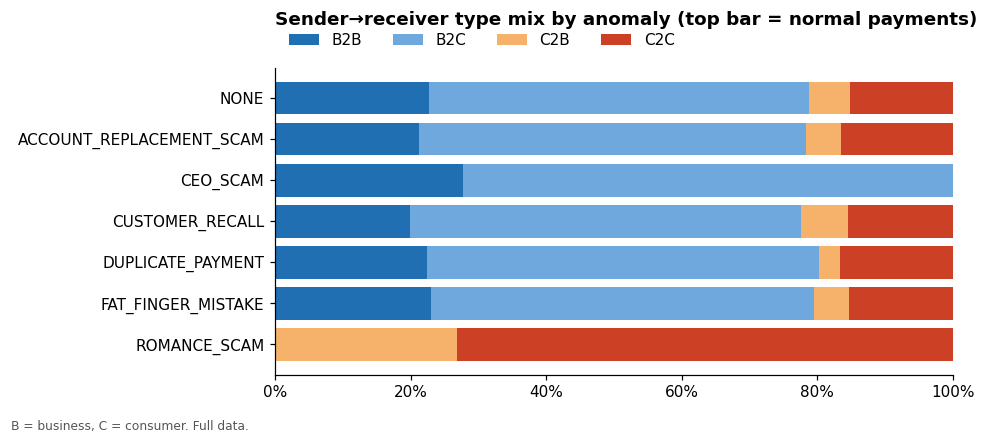

In [28]:
# A-1: sender->receiver pair mix of each anomaly vs normal payments
mix = q("SELECT anomaly, pair, count(*) AS n FROM p GROUP BY ALL")
mix = mix.pivot(index="anomaly", columns="pair", values="n").fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)
mix = mix.loc[["NONE"] + [i for i in mix.index if i != "NONE"]]
fig, ax = plt.subplots(figsize=(9, 4))
left = np.zeros(len(mix))
for col, colr in zip(mix.columns, ["#1F6FB2", "#6FA8DC", "#F6B26B", "#CC4125"]):
    ax.barh(mix.index, mix[col], left=left, color=colr, label=col); left += mix[col].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(ncol=4, bbox_to_anchor=(0, 1.02), loc="lower left", frameon=False)
ax.set_title("Sender→receiver type mix by anomaly (top bar = normal payments)", pad=28)
finish(fig, "A1_pair_mix_by_anomaly", "B = business, C = consumer. Full data.")

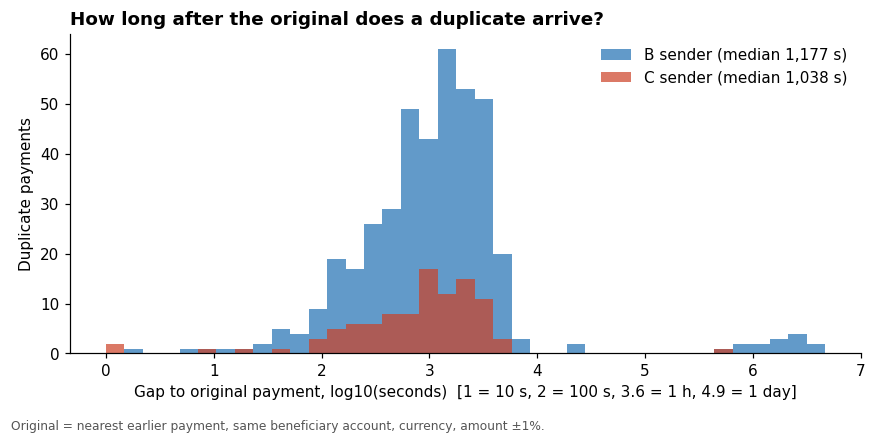

In [29]:
# A-2: duplicate gap distribution by sender type
g = q("SELECT ORDERING_TYPE AS sender_type, gap_s FROM dup_match")
if len(g):
    fig, ax = plt.subplots(figsize=(8, 4))
    bins = np.linspace(0, np.log10(g.gap_s.max() + 1) + 0.1, 40)
    for t, colr in [("B", HI), ("C", "#CC4125")]:
        s = g[g.sender_type == t].gap_s
        if len(s):
            ax.hist(np.log10(s + 1), bins=bins, alpha=.7, color=colr, label=f"{t} sender (median {s.median():,.0f} s)")
    ax.set_xlabel("Gap to original payment, log10(seconds)  [1 = 10 s, 2 = 100 s, 3.6 = 1 h, 4.9 = 1 day]")
    ax.set_ylabel("Duplicate payments"); ax.legend(frameon=False)
    ax.set_title("How long after the original does a duplicate arrive?")
    finish(fig, "A2_duplicate_gap", "Original = nearest earlier payment, same beneficiary account, currency, amount ±1%.")

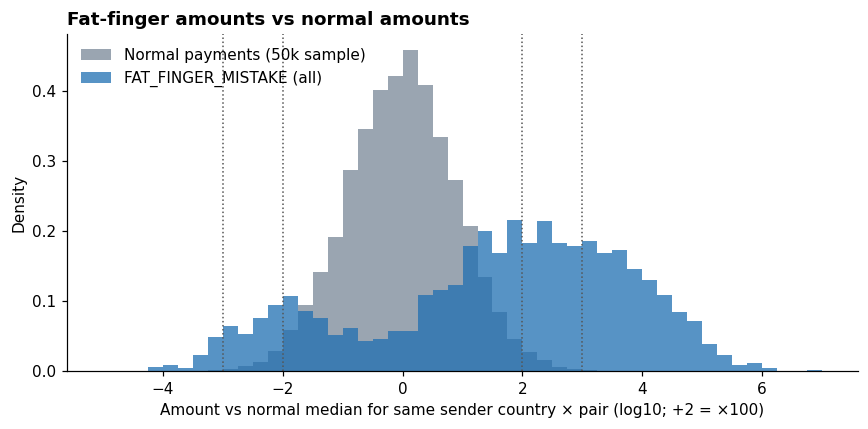

In [30]:
# A-3: fat-finger amount shift vs normal
s = q("""
SELECT anomaly = 'FAT_FINGER_MISTAKE' AS ff, log10(USD_AMOUNT) - b.med_log10 AS sh
FROM (SELECT * FROM p WHERE anomaly = 'FAT_FINGER_MISTAKE'
      UNION ALL SELECT * FROM (SELECT * FROM p WHERE anomaly='NONE') USING SAMPLE reservoir(50000 ROWS) REPEATABLE (42)) x
JOIN amt_base b USING (o_cc, pair) WHERE USD_AMOUNT > 0""")
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(np.floor(s.sh.min()), np.ceil(s.sh.max()) + 0.25, 0.25)
ax.hist(s[~s.ff].sh, bins=bins, density=True, color=BASE, label="Normal payments (50k sample)")
ax.hist(s[s.ff].sh, bins=bins, density=True, color=HI, alpha=.75, label="FAT_FINGER_MISTAKE (all)")
for k in (-3, -2, 2, 3):
    ax.axvline(k, ls=":", c=GREY, lw=1)
ax.set_xlabel("Amount vs normal median for same sender country × pair (log10; +2 = ×100)")
ax.set_ylabel("Density"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Fat-finger amounts vs normal amounts")
finish(fig, "A3_fatfinger_shift")

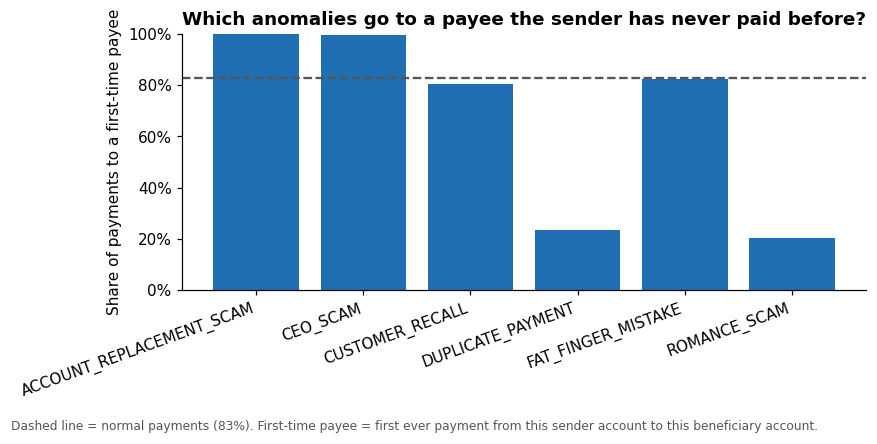

In [31]:
# A-4: first-time payee share by anomaly vs normal (baseline line)
pf = prof.set_index("grp")
base = pf.loc["NONE (all)", "first_time_payee"]
an = pf.drop(index=[i for i in pf.index if i.startswith("NONE")])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(an.index, an.first_time_payee, color=HI)
ax.axhline(base, ls="--", c=GREY)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Share of payments to a first-time payee"); plt.xticks(rotation=20, ha="right")
ax.set_title("Which anomalies go to a payee the sender has never paid before?")
finish(fig, "A4_first_time_payee", f"Dashed line = normal payments ({base:.0%}). First-time payee = first ever payment from this sender account to this beneficiary account.")

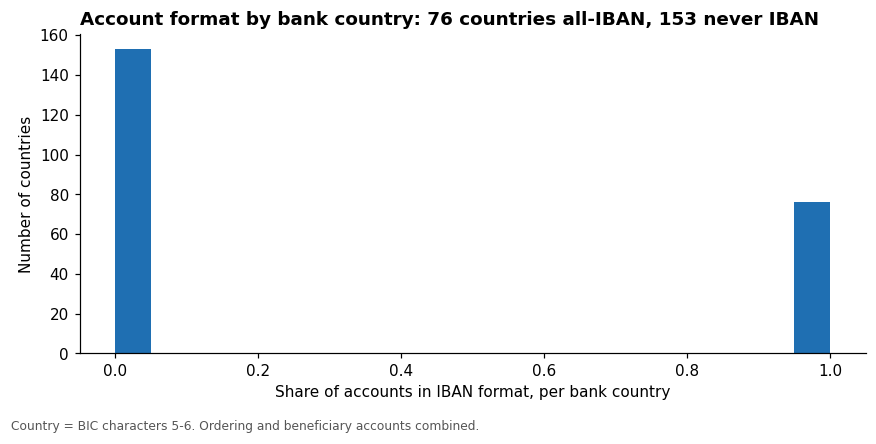

In [32]:
# AC-1: IBAN share per bank country is all-or-nothing?
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(iban_cc.iban_share, bins=20, color=HI)
ax.set_xlabel("Share of accounts in IBAN format, per bank country"); ax.set_ylabel("Number of countries")
ax.set_title(f"Account format by bank country: {(iban_cc.iban_share > .99).sum()} countries all-IBAN, "
             f"{(iban_cc.iban_share < .01).sum()} never IBAN")
finish(fig, "AC1_iban_share_by_country", "Country = BIC characters 5-6. Ordering and beneficiary accounts combined.")

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


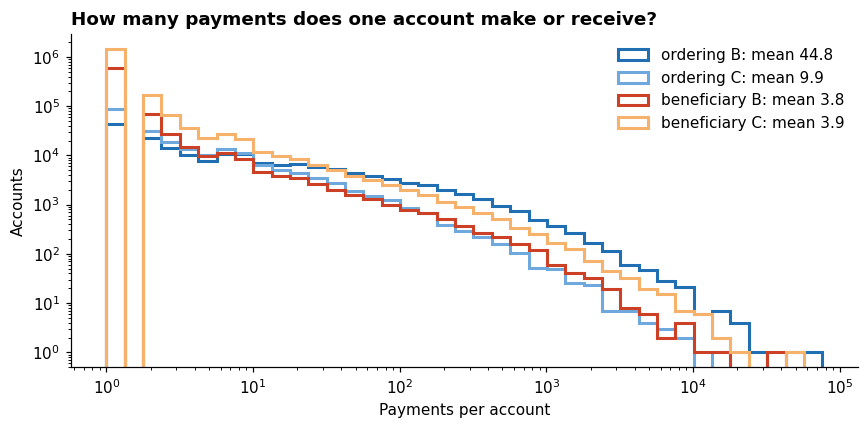

In [33]:
# AC-2: payments per account, by role x party type
acts = q("""SELECT role, typ, n, count(*) AS accounts
            FROM (SELECT role, typ, acct, count(*) AS n FROM acct_long2 GROUP BY ALL) GROUP BY ALL""")
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(acts.n.max() + 1), 40)
for (r, t), colr in zip([("ordering", "B"), ("ordering", "C"), ("beneficiary", "B"), ("beneficiary", "C")],
                        [HI, "#6FA8DC", "#CC4125", "#F6B26B"]):
    g = acts[(acts.role == r) & (acts.typ == t)]
    if len(g):
        mean = (g.n * g.accounts).sum() / g.accounts.sum()
        ax.hist(g.n, bins=bins, weights=g.accounts, histtype="step", lw=2, color=colr, label=f"{r} {t}: mean {mean:.1f}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Payments per account"); ax.set_ylabel("Accounts")
ax.legend(frameon=False); ax.set_title("How many payments does one account make or receive?")
finish(fig, "AC2_payments_per_account")

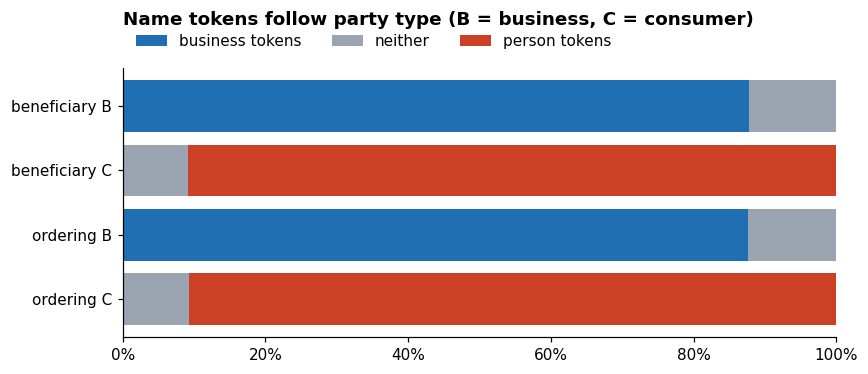

In [34]:
# D-1: name token class vs party type
piv = nc.pivot_table(index=["side", "typ"], columns="name_class", values="share").fillna(0)
fig, ax = plt.subplots(figsize=(8, 3.5))
left = np.zeros(len(piv)); labels = [f"{s} {t}" for s, t in piv.index]
for col, colr in zip(piv.columns, [HI, BASE, "#CC4125"]):
    ax.barh(labels, piv[col], left=left, color=colr, label=col); left += piv[col].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.invert_yaxis()
ax.legend(ncol=3, bbox_to_anchor=(0, 1.02), loc="lower left", frameon=False)
ax.set_title("Name tokens follow party type (B = business, C = consumer)", pad=28)
finish(fig, "D1_name_tokens_by_party_type")

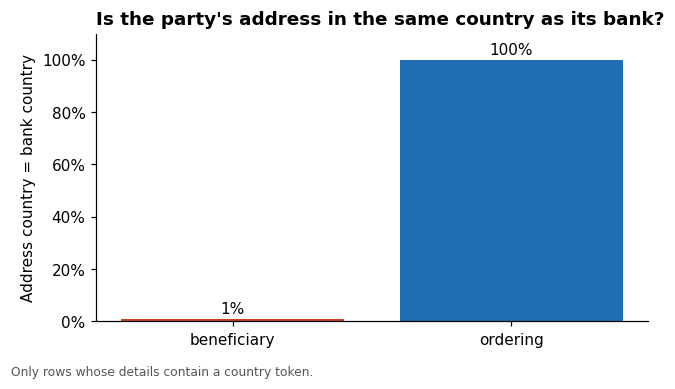

In [35]:
# D-2: address country = bank country, sender vs receiver
dd = det.groupby("side").apply(lambda g: np.average(g.addr_country_eq_bank.fillna(0), weights=g.n * g.has_country), include_groups=False)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dd.index, dd.values, color=[HI if i == "ordering" else "#CC4125" for i in dd.index])
for i, v in enumerate(dd.values):
    ax.text(i, v + .02, f"{v:.0%}", ha="center")
ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Address country = bank country")
ax.set_title("Is the party's address in the same country as its bank?")
finish(fig, "D2_address_vs_bank_country", "Only rows whose details contain a country token.")

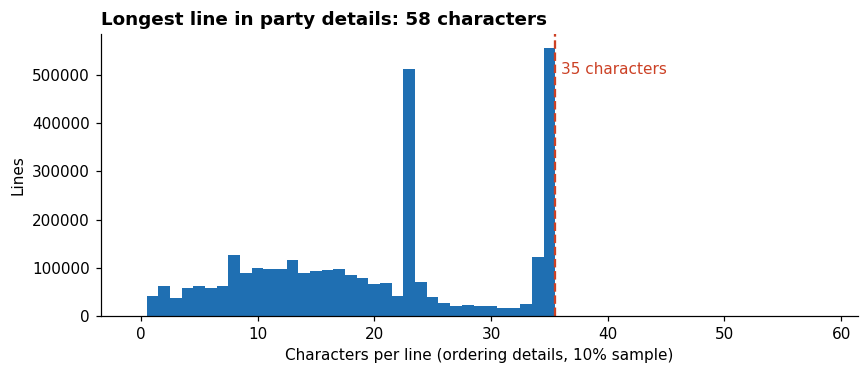

In [36]:
# D-3: line-length ceiling
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(linelen.line_len, linelen.n, color=HI, width=1)
ax.axvline(35.5, ls="--", c="#CC4125"); ax.text(36, linelen.n.max() * .9, "35 characters", color="#CC4125")
ax.set_xlabel("Characters per line (ordering details, 10% sample)"); ax.set_ylabel("Lines")
ax.set_title(f"Longest line in party details: {int(linelen.line_len.max())} characters")
finish(fig, "D3_line_length")

## 8. Rules log
Write one row per rule **after** reading the tables above, in `outputs/tables/rules/rules_03_anomalies.csv`. Use the template: condition → effect → size → scope → exceptions, then observed evidence, real-world interpretation, rejected alternative and confidence (Confirmed / Strong / Partial / Rejected).
`combine_rules()` merges this file with the other notebooks' rules into `outputs/tables/rules_log.csv`.

In [37]:
RULES_COLS = ["id", "group", "when_condition", "then_effect", "size", "scope_rows_pct", "exceptions",
              "observed_evidence_table_or_chart", "interpretation_real_world", "rejected_alternative", "confidence"]
rules_path = RULES / "rules_03_anomalies.csv"
if not rules_path.exists():          # never overwrite your filled-in rules
    pd.DataFrame([{
        "id": "A2-example", "group": "Anomalies",
        "when_condition": "Payment labelled DUPLICATE_PAYMENT and sender is a business",
        "then_effect": "An earlier payment exists with same sender, beneficiary, currency and amount",
        "size": "median gap = ?? s", "scope_rows_pct": "?? of ?? duplicates (??%)",
        "exceptions": "C senders: different sender account (partner) and longer gap?",
        "observed_evidence_table_or_chart": "a_duplicates_vs_control.csv; A2_duplicate_gap.png",
        "interpretation_real_world": "INTERPRETATION: back-office race condition re-submits the same payment",
        "rejected_alternative": "Exact copy of the row (rejected: timestamps differ)",
        "confidence": "Confirmed / Strong / Partial / Rejected"}], columns=RULES_COLS).to_csv(rules_path, index=False)
display(pd.read_csv(rules_path))
combine_rules()

,id,group,when_condition,then_effect,size,scope_rows_pct,exceptions,observed_evidence_table_or_chart,interpretation_real_world,rejected_alternative,confidence
0,A2-example,Anomalies,Payment labelled DUPLICATE_PAYMENT and sender ...,"An earlier payment exists with same sender, be...",median gap = ?? s,?? of ?? duplicates (??%),C senders: different sender account (partner) ...,a_duplicates_vs_control.csv; A2_duplicate_gap.png,INTERPRETATION: back-office race condition re-...,Exact copy of the row (rejected: timestamps di...,Confirmed / Strong / Partial / Rejected


,id,group,rule,test,value,verdict,evidence_files,interpretation,source,when_condition,then_effect,size,scope_rows_pct,exceptions,rejected_alternative
0,A2-example,Anomalies,Payment labelled DUPLICATE_PAYMENT and sender ...,NaN,median gap = ?? s,Confirmed / Strong / Partial / Rejected,a_duplicates_vs_control.csv; A2_duplicate_gap.png,INTERPRETATION: back-office race condition re-...,rules_03_anomalies.csv,Payment labelled DUPLICATE_PAYMENT and sender ...,"An earlier payment exists with same sender, be...",median gap = ?? s,?? of ?? duplicates (??%),C senders: different sender account (partner) ...,Exact copy of the row (rejected: timestamps di...
1,R-CCY1,Currency,Payments are made in the sender country's loca...,full data; local currency inferred in-sample,89.4% sender-local; only 4.2% use the receiver...,Partial (exceptions not yet explained),ccy1_currency_choice.png,The sender's bank debits in its home currency;...,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
2,R-CCY2,Currency,Direct payments: 1 conversion if sender and re...,prediction accuracy on all Direct rows,97.8%,Strong,ccy2_direct_conversion_rule.png,"With only two banks, FX happens once, and only...",rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
3,R-CCY3,Currency,Conversions never exceed the number of hops (p...,share of all rows,100.00%,Confirmed,ccy3_conversions_by_hops.csv,Each correspondent bank can convert at most once,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
4,R-AMT1,Amount,Amounts are log-normal: ln(amount) is normal w...,skew / excess kurtosis / sd of ln residual,"skew -0.016, kurtosis 0.024, sd 2.08",Confirmed,amt1_lognormal_by_pair.png,Payment sizes built from many multiplying fact...,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
5,R-AMT2,Amount,Each business party (sender or receiver) multi...,"ln effect within sender country, 95% cluster-b...","sender 1.999 [1.980, 2.019]; receiver 2.002 [1...",Confirmed,amt2_business_multiplier.png,Businesses pay invoices and payroll; consumers...,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
6,R-AMT3,Amount,The sender's country sets the base amount; the...,R² sender country vs extra R² of receiver country,0.131 vs 0.0003,Confirmed,amt3_country_base_amount.png,Payment size scales with the income level of t...,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
7,R-BC1,Business/consumer,Sender type and receiver type are assigned ind...,"chi-square p, Cramér's V","p = 0.67, V = 0.0003",Confirmed,bc1_type_independence.png,Who pays and who gets paid are separate draws,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
8,R-BC2,Business/consumer,Timestamps follow the sender's local working d...,"share 07:00-19:59 local vs UTC; V(hour, sender...",74.5% local vs 65.0% UTC; V = 0.024,Strong (time zone is approximate),bc2_local_hour_profile.png,Payments are entered and batched in office hours,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
9,R-BC3,Business/consumer,Business sender accounts send more payments th...,"payments per (sender BIC, account) over the da...",B 44.8 vs C 9.9 (x4.5),Confirmed,bc3_activity_per_account.png,Companies pay many suppliers and staff,rules_04_core.csv,NaN,NaN,NaN,NaN,NaN,NaN
